# 로지스틱 회귀와 다중 분류

합성 데이터로 손실함수와 기울기를 구현하고, 학습된 모델의 분류 경계 확인.

표시되는 교차 엔트로피는 학습 데이터의 오차. 새로운 데이터에 대한 성능 평가와 구분. 커널 초기화 후 순서대로 실행.

In [1]:
# 기본 설정
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from scipy.optimize import minimize

np.set_printoptions(precision=3, suppress=True)

## 2. 1차원 입력 2클래스 분류

입력 `X`는 무게, 타깃 `T`는 클래스 번호
`T=0`는 암컷, `T=1`는 수컷

In [2]:
# 1차원 입력 2클래스 분류 문제 데이터 생성
# 곤충 N마리의 데이터, 무게는 x_n, 성별은 t_n으로 하고 0이면 암컷, 1이면 수컷
np.random.seed(seed=0)  # 난수 고정

# 데이터 생성을 위한 파라미터
X_min = 0
X_max = 2.5
X_n = 30

Dist_s = [0.4, 0.8]  # 분포의 시작 지점 [0]: 암컷, [1]: 수컷
Dist_w = [0.8, 1.6]  # 분포의 폭 [0]: 암컷, [1]: 수컷
Pi = 0.5             # 클래스 0(암컷)의 비율

X_col = ['cornflowerblue', 'gray']  # Plot 시 암컷 데이터[0], 수컷 데이터[1] 색상

# 입력 데이터와 타깃 데이터 저장을 위한 변수
X = np.zeros(X_n)  # 입력 데이터
T = np.zeros(X_n, dtype=np.uint8)  # 타깃 데이터(정수값 저장)

for n in range(X_n):
    wk = np.random.rand()
    T[n] = 0 * (wk < Pi) + 1 * (wk >= Pi)
    # 암컷이 될 확률 Pi = 0.5로 하여 무작위로 결정

    X[n] = np.random.rand() * Dist_w[T[n]] + Dist_s[T[n]]
    # 질량은 암컷이라면 0.4~1.2, 수컷이라면 0.8~2.4의 균일한 분포에서 샘플링

print('X =', np.round(X, 2))
print('T =', T)
print('class 0 count =', np.sum(T == 0), ', class 1 count =', np.sum(T == 1))

X = [1.94 1.67 0.92 1.11 1.41 1.65 2.28 0.47 1.07 2.19 2.08 1.02 0.91 1.16
 1.46 1.02 0.85 0.89 1.79 1.89 0.75 0.9  1.87 0.5  0.69 1.5  0.96 0.53
 1.21 0.6 ]
T = [1 1 0 0 1 1 1 0 0 1 1 0 0 0 1 0 0 0 1 1 0 1 1 0 0 1 1 0 1 0]
class 0 count = 15 , class 1 count = 15


## 3. 데이터 분포 표시

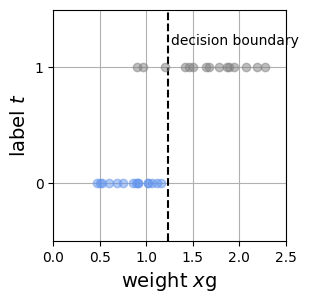

In [3]:
# 데이터 분포 표시
def show_data1(x, t):
    K = np.max(t) + 1

    for k in range(K):
        plt.plot(x[t == k], t[t == k], X_col[k], alpha=0.5, linestyle='none', marker='o')
        # t == k일 때, x와 t만 추출하여 플롯한다.
        plt.grid(True)
        plt.ylim(-0.5, 1.5)
        plt.xlim(X_min, X_max)
        plt.yticks([0, 1])
        plt.xlabel('weight $x$g', fontsize=14)
        plt.ylabel('label $t$', fontsize=14)

fig = plt.figure(figsize=(3, 3))

# 학습전 결정 경계 임의 표시
boundary = 1.24
plt.axvline(boundary, color='black', linestyle='--')
plt.text(boundary + 0.03, 1.2, 'decision boundary', fontsize=10)

show_data1(X, T)
plt.show()

### 4. 로지스틱 회귀 모델

`y = 1 / (1 + exp(-(w0*x + w1)))` 형태의 시그모이드 모델을 사용합니다.

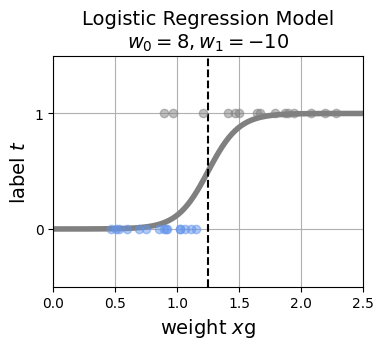

Boundary = 1.25 g


In [4]:
# 로지스틱 회귀 모델

def logistic(x, w):
    y = 1 / (1 + np.exp(-(w[0] * x + w[1])))
    return y


def show_logistic(w):
    xb = np.linspace(X_min, X_max, 100)
    y = logistic(xb, w)
    plt.plot(xb, y, color='gray', linewidth=4)

    # 결정 경계(decision boundary)
    i = np.min(np.where(y > 0.5))
    B = (xb[i - 1] + xb[i]) / 2

    plt.plot([B, B], [-0.5, 1.5], color='k', linestyle='--')
    plt.title('Logistic Regression Model\n$w_0={0}, w_1={1}$'.format(w[0], w[1]), fontsize=14)
    plt.grid(True)

    return B

# 예시 매개변수로 모델 모양 확인
W = [8, -10]
plt.figure(figsize=(4, 3))
B = show_logistic(W)
show_data1(X, T)
plt.show()
print('Boundary = {:.2f} g'.format(B))

### 교차 엔트로피 오차(cross-entropy error)

분류 모델에서는 평균제곱오차 대신 교차 엔트로피 오차사용

In [5]:
# 평균 교차 엔트로피 오차(cross-entropy error function)

def cee_logistic(w, x, t):
    y = logistic(x, w)
    y = np.clip(y, 1e-12, 1 - 1e-12)
    cee = 0

    for n in range(len(y)):
        cee = cee - (t[n] * np.log(y[n]) + (1 - t[n]) * np.log(1 - y[n]))

    cee = cee / X_n  # 평균
    return cee

# w0=1, w1=1일 때 CEE
W = [1, 1]
print('CEE =', cee_logistic(W, X, T))

CEE = 1.0288191541851066


### 교차 엔트로피 오차 표면과 등고선

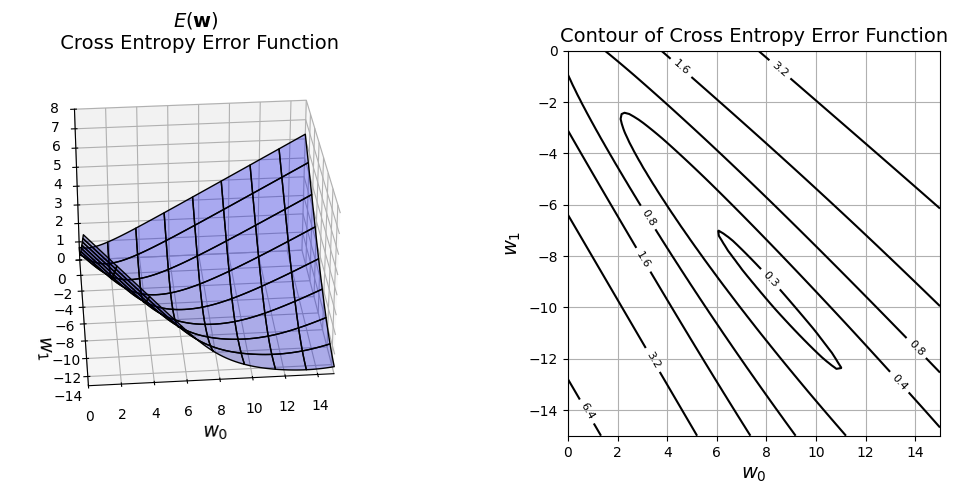

In [6]:
# 평균 교차 엔트로피 오차의 plot
# 계산
xn = 80  # 등고선의 표시 해상도
w_range = np.array([[0, 15], [-15, 0]])
x0 = np.linspace(w_range[0, 0], w_range[0, 1], xn)
x1 = np.linspace(w_range[1, 0], w_range[1, 1], xn)
xx0, xx1 = np.meshgrid(x0, x1)
C = np.zeros((len(x1), len(x0)))
w = np.zeros(2)

for i0 in range(xn):
    for i1 in range(xn):
        w[0] = x0[i0]
        w[1] = x1[i1]
        C[i1, i0] = cee_logistic(w, X, T)

# 표시
plt.figure(figsize=(12, 5))
plt.subplots_adjust(wspace=0.5)
ax = plt.subplot(1, 2, 1, projection='3d')
ax.plot_surface(xx0, xx1, C, color='blue', edgecolor='black', rstride=10, cstride=10, alpha=0.3)
ax.set_xlabel('$w_0$', fontsize=14)
ax.set_ylabel('$w_1$', fontsize=14)
ax.set_xlim(0, 15)
ax.set_ylim(-15, 0)
ax.set_zlim(0, 8)
ax.view_init(30, -95)
ax.set_title('$E(\mathbf{w})$\n Cross Entropy Error Function', fontsize=14)

plt.subplot(1, 2, 2)
cont = plt.contour(xx0, xx1, C, 20, colors='black', levels=[0.26, 0.4, 0.8, 1.6, 3.2, 6.4])
cont.clabel(fmt='%1.1f', fontsize=8)
plt.xlabel('$w_0$', fontsize=14)
plt.ylabel('$w_1$', fontsize=14)
plt.title('Contour of Cross Entropy Error Function', fontsize=14)
plt.grid(True)
plt.show()

### 학습 규칙과 경사하강법

교차 엔트로피 오차의 그래디언트를 구한 뒤 `scipy.optimize.minimize`로 최적 매개변수를 찾습니다.

In [7]:
# 평균 교차 엔트로피 오차의 편미분

def dcee_logistic(w, x, t):
    y = logistic(x, w)
    dcee = np.zeros(2)

    for n in range(len(y)):
        dcee[0] = dcee[0] + (y[n] - t[n]) * x[n]
        dcee[1] = dcee[1] + (y[n] - t[n])

    dcee = dcee / X_n
    return dcee

W = [1, 1]
np.set_printoptions(precision=8)
print('dCEE =', dcee_logistic(W, X, T))

dCEE = [0.30857905 0.39485474]


In [8]:
# 로지스틱 회귀 모델의 경사하강법

def fit_logistic(w_init, x, t):
    res = minimize(cee_logistic, w_init, args=(x, t), jac=dcee_logistic, method='CG')
    return res.x

W_init = [1, -1]
W = fit_logistic(W_init, X, T)
cee = cee_logistic(W, X, T)

print('w0 = {}, w1 = {}'.format(W[0], W[1]))
print('CEE = {}'.format(cee))

w0 = 8.17647664391449, w1 = -9.382246201793313
CEE = 0.25104463379423875


### 학습된 로지스틱 회귀 모델 표시

w0 = 8.18, w1 = -9.38
CEE = 0.25
Boundary = 1.15 g


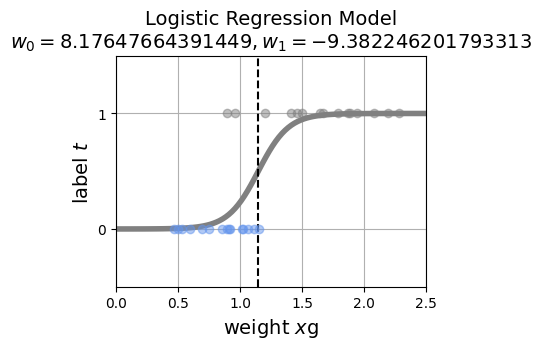

In [9]:
plt.figure(1, figsize=(4, 3))
print('w0 = {0:.2f}, w1 = {1:.2f}'.format(W[0], W[1]))
B = show_logistic(W)
show_data1(X, T)
plt.xlim(X_min, X_max)
plt.ylim(-0.5, 1.5)
plt.xlabel('weight $x$g', fontsize=14)
plt.ylabel('label $t$', fontsize=14)
cee = cee_logistic(W, X, T)
print('CEE = {0:.2f}'.format(cee))
print('Boundary = {0:.2f} g'.format(B))
plt.show()

## 2. 2차원 입력 2클래스/3클래스 분류

입력 `X`는 2차원 좌표입니다. `T2`는 2클래스용 원-핫 타깃, `T3`는 3클래스용 원-핫 타깃입니다.

In [10]:
# %reset
# import numpy as np
# import matplotlib.pyplot as plt

# 2클래스 분류, 3클래스 분류 문제 데이터 생성-(1)
np.random.seed(seed=1)

# 데이터 생성을 위한 파라미터
N = 100  # 데이터의 수
K = 3    # 분포의 수(3클래스 분류)
X_range0 = [-3, 3]  # X0 범위
X_range1 = [-3, 3]  # X1 범위
Mu = np.array([[-0.5, -0.5], [0.5, 1.0], [1, -0.5]])       # 분포의 중심
Sig = np.array([[0.7, 0.7], [0.8, 0.3], [0.3, 0.8]])       # 분포의 분산
Pi = np.array([0.4, 0.8, 1])                               # 각 분포의 비율

# 입력 데이터와 타깃 레이블 변수 생성
X = np.zeros((N, 2))
T3 = np.zeros((N, 3), dtype=np.uint8)  # one-hot-encoding 3클래스
T2 = np.zeros((N, 2), dtype=np.uint8)  # one-hot-encoding 2클래스

In [11]:
# 2클래스 분류, 3클래스 분류 문제 데이터 생성-(2)
for n in range(N):
    wk = np.random.rand()

    # Pi[k]보다 작으면 클래스 k로 지정
    for k in range(K):
        if wk < Pi[k]:
            T3[n, k] = 1
            break

    # 클래스가 결정된 뒤, 클래스마다 각각 다른 가우스 분포로 입력 데이터(X0, X1)를 생성
    for k in range(2):
        value = np.random.randn() * Sig[T3[n, :] == 1, k] + Mu[T3[n, :] == 1, k]
        X[n, k] = value

# 3클래스 타깃 레이블 생성완료: T3

# 2클래스 타깃 레이블 생성: T2
T2[:, 0] = T3[:, 0]
T2[:, 1] = T3[:, 1] | T3[:, 2]

# 마지막 5개의 입력 데이터 출력
print(X[:5, :])
# 마지막 5개의 타겟 레이블(2클래스 분류) 출력
print(T2[:5, :])
# 마지막 5개의 타겟 레이블(3클래스 분류) 출력
print(T3[:5, :])

[[-0.14173827  0.86533666]
 [-0.86972023 -1.25107804]
 [-2.15442802  0.29474174]
 [ 0.75523128  0.92518889]
 [-1.10193462  0.74082534]]
[[0 1]
 [1 0]
 [1 0]
 [0 1]
 [1 0]]
[[0 1 0]
 [1 0 0]
 [1 0 0]
 [0 1 0]
 [1 0 0]]


### 2클래스/3클래스 데이터 생성

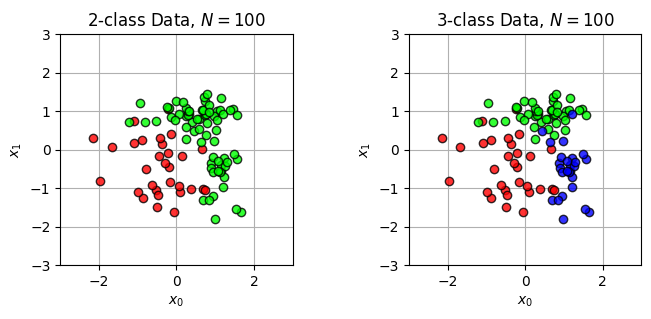

In [12]:
# 데이터 표시
def show_data2(x, t):
    wk, K = t.shape
    c = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]  # 컬러 값 설정 [r, g, b]

    for k in range(K):
        plt.plot(x[t[:, k] == 1, 0], x[t[:, k] == 1, 1], linestyle='none',
                 markeredgecolor='black', marker='o', color=c[k], alpha=0.8)
    plt.grid(True)

plt.figure(figsize=(7.5, 3))
plt.subplots_adjust(wspace=0.5)
plt.subplot(1, 2, 1)
show_data2(X, T2)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('2-class Data, $N=100$')

plt.subplot(1, 2, 2)
show_data2(X, T3)
plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')
plt.title('3-class Data, $N=100$')
plt.show()

### 2차원 입력 데이터의 로지스틱 회귀 모델

In [13]:
# 2D 로지스틱 회귀 모델

def logistic2(x0, x1, w):
    an = w[0] * x0 + w[1] * x1 + w[2]
    y = 1 / (1 + np.exp(-(an)))
    return y

### 2D 로지스틱 모델 3D 표시

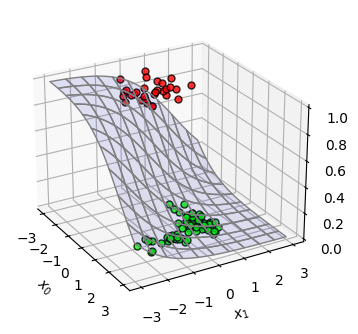

In [14]:
# 모델 3D 보기
def show3d_logistic2(ax, w):
    xn = 50
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    y = logistic2(xx0, xx1, w)
    ax.plot_surface(xx0, xx1, y, color='blue', edgecolor='gray', rstride=5, cstride=5, alpha=0.1)


def show_data2_3d(ax, x, t):
    c = [[1, 0, 0], [0, 1, 0]]

    for i in range(2):
        ax.plot(x[t[:, i] == 1, 0], x[t[:, i] == 1, 1], 1 - i, marker='o', color=c[i],
                markeredgecolor='black', linestyle='none', markersize=5, alpha=0.8)

    ax.set_xlabel('$x_0$')
    ax.set_ylabel('$x_1$')
    ax.set_zlabel('$y$')
    ax.view_init(elev=25, azim=-30)

# test
plt.figure(figsize=(5, 4))
Ax = plt.subplot(1, 1, 1, projection='3d')
W = [-1, -1, -1]
show3d_logistic2(Ax, W)
show_data2_3d(Ax, X, T2)
plt.show()

### 2D 로지스틱 모델 등고선 표시

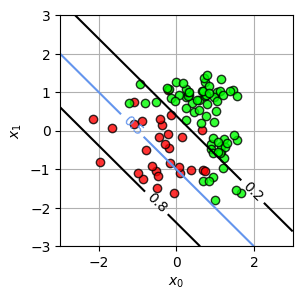

In [15]:
# 모델 등고선 보기
def show_contour_logistic2(w):
    xn = 30  # 매개 변수의 분할 수
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)
    xx0, xx1 = np.meshgrid(x0, x1)
    y = logistic2(xx0, xx1, w)
    cont = plt.contour(xx0, xx1, y, levels=(0.2, 0.5, 0.8), colors=['k', 'cornflowerblue', 'k'])
    cont.clabel(fmt='%1.1f', fontsize=10)
    plt.xlabel('$x_0$')
    plt.ylabel('$x_1$')
    plt.grid(True)

# test
plt.figure(figsize=(3, 3))
W = [-1, -1, -1]
show_data2(X, T2)
show_contour_logistic2(W)
plt.show()

### 2차원 2클래스 로지스틱 회귀 모델의 CEE와 그래디언트

In [16]:
# 2차원 입력 2클래스 로지스틱 회귀 모델의 크로스 엔트로피 오차

def cee_logistic2(w, x, t):
    X_n = x.shape[0]
    y = logistic2(x[:, 0], x[:, 1], w)
    y = np.clip(y, 1e-12, 1 - 1e-12)
    cee = 0

    for n in range(len(y)):
        cee = cee - (t[n, 0] * np.log(y[n]) + (1 - t[n, 0]) * np.log(1 - y[n]))

    cee = cee / X_n
    return cee

# 2차원 입력 2클래스 로지스틱 회귀 모델의 크로스 엔트로피 오차의 그래디언트

def dcee_logistic2(w, x, t):
    X_n = x.shape[0]
    y = logistic2(x[:, 0], x[:, 1], w)
    dcee = np.zeros(3)

    for n in range(len(y)):
        dcee[0] = dcee[0] + (y[n] - t[n, 0]) * x[n, 0]
        dcee[1] = dcee[1] + (y[n] - t[n, 0]) * x[n, 1]
        dcee[2] = dcee[2] + (y[n] - t[n, 0])

    dcee = dcee / X_n
    return dcee

# w0, w1, w2가 -1일 때 그래디언트
W = [-1, -1, -1]
print('dCEE =', dcee_logistic2(W, X, T2))

dCEE = [ 0.10272008  0.04450983 -0.06307245]


In [17]:
# 평균 교차 엔트로피 오차 함수의 최적화

def fit_logistic2(w_init, x, t):
    res = minimize(cee_logistic2, w_init, args=(x, t), jac=dcee_logistic2, method='CG')
    return res.x

# 초기 매개변수 w0=-1, w1=0, w2=0일 때 경사하강법 결과
W_init = [-1, 0, 0]
W = fit_logistic2(W_init, X, T2)
print('w0 = {0: .2f}, w1 = {1: .2f}, w2 = {2: .2f}'.format(W[0], W[1], W[2]))

cee = cee_logistic2(W, X, T2)
print('CEE = {0: .2f}'.format(cee))

w0 = -3.70, w1 = -2.54, w2 = -0.28
CEE =  0.22


### 학습된 2D 로지스틱 회귀 모델 표시

w0 = -3.70, w1 = -2.54, w2 = -0.28
CEE =  0.22


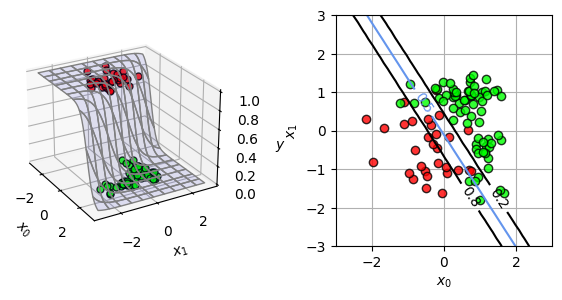

In [18]:
plt.figure(1, figsize=(7, 3))
plt.subplots_adjust(wspace=0.5)

Ax = plt.subplot(1, 2, 1, projection='3d')
W_init = [-1, 0, 0]
W = fit_logistic2(W_init, X, T2)
print('w0 = {0: .2f}, w1 = {1: .2f}, w2 = {2: .2f}'.format(W[0], W[1], W[2]))
show3d_logistic2(Ax, W)
Ax.set_xlabel('$x_0$')
Ax.set_ylabel('$x_1$')

show_data2_3d(Ax, X, T2)
cee = cee_logistic2(W, X, T2)
print('CEE = {0: .2f}'.format(cee))

Ax = plt.subplot(1, 2, 2)
show_data2(X, T2)
show_contour_logistic2(W)
Ax.set_xlabel('$x_0$')
Ax.set_ylabel('$x_1$')

plt.show()

## 3. 2차원 입력 3클래스 분류

3개 클래스를 분류하기 위해 시그모이드 대신 소프트맥스 함수 사용

In [19]:
# 소프트맥스 함수(3클래스 분류)

def softmax(x0, x1, x2):
    u = np.exp(x0) + np.exp(x1) + np.exp(x2)
    y0 = np.exp(x0) / u
    y1 = np.exp(x1) / u
    y2 = np.exp(x2) / u
    return y0, y1, y2

y = softmax(x0=2, x1=1, x2=-1)
print(np.round(y, 2))
print(np.sum(y))  # softmax 함수의 모든 출력의 합은 1.0

[0.71 0.26 0.04]
1.0


In [20]:
# 3클래스 분류용 로지스틱 회귀 모델
# 활성화 함수를 시그모이드 대신 소프트맥스 함수로 사용

def logistic3(x0, x1, w):
    K = 3
    w = np.asarray(w).reshape((3, 3))
    n = len(x1)
    a = np.zeros((n, K))  # 입력 데이터 수 x 클래스 수 만큼 array 생성

    for k in range(K):
        a[:, k] = w[k, 0] * x0 + w[k, 1] * x1 + w[k, 2]

    exp_a = np.exp(a - np.max(a, axis=1, keepdims=True))
    u = np.sum(exp_a, axis=1)
    soft = exp_a.T / u
    y = soft.T

    return y

W = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
y = logistic3(X[:10, 0], X[:10, 1], W)
print(np.round(y, 3))
print('row sums =', np.round(np.sum(y, axis=1), 3))

[[0.    0.006 0.994]
 [0.965 0.033 0.001]
 [0.925 0.07  0.005]
 [0.    0.    1.   ]
 [0.019 0.126 0.856]
 [0.    0.002 0.998]
 [0.    0.002 0.998]
 [0.01  0.095 0.894]
 [0.    0.001 0.999]
 [0.003 0.05  0.948]]
row sums = [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [21]:
# 3클래스 분류 로지스틱 회귀 모델의 교차 엔트로피 오차

def cee_logistic3(w, x, t):
    X_n = x.shape[0]
    y = logistic3(x[:, 0], x[:, 1], w)
    y = np.clip(y, 1e-12, 1 - 1e-12)

    cee = 0
    N, K = y.shape

    for n in range(N):
        for k in range(K):
            cee = cee - (t[n, k] * np.log(y[n, k]))

    cee = cee / X_n
    return cee

W = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
cee = cee_logistic3(W, X, T3)
print(cee)

3.9824582404787288


In [22]:
# 3클래스 분류 로지스틱 회귀 모델의 교차 엔트로피 오차의 그래디언트

def dcee_logistic3(w, x, t):
    X_n = x.shape[0]
    y = logistic3(x[:, 0], x[:, 1], w)
    dcee = np.zeros((3, 3))  # shape: 클래스 수, 입력 데이터 차원 + 1
    N, K = y.shape

    for n in range(N):
        for k in range(K):
            dcee[k, :] = dcee[k, :] - (t[n, k] - y[n, k]) * np.r_[x[n, :], 1]

    dcee = dcee / X_n
    return dcee.reshape(-1)

W = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9])
dcee = dcee_logistic3(W, X, T3)
print(dcee)

[ 0.03778433  0.03708109 -0.1841851  -0.21235188 -0.44408101 -0.38340835
  0.17456754  0.40699992  0.56759346]


In [23]:
# 3클래스 분류 로지스틱 회귀 모델의 경사 하강법

def fit_logistic3(w_init, x, t):
    res = minimize(cee_logistic3, np.asarray(w_init).reshape(-1), args=(x, t),
                   jac=dcee_logistic3, method='CG')
    return res.x

W_init = np.zeros((3, 3))
W = fit_logistic3(W_init, X, T3)

print(np.round(W.reshape((3, 3)), 2))
cee = cee_logistic3(W, X, T3)
print('CEE = {:.2f}'.format(cee))

[[-3.2  -2.69  2.25]
 [-0.49  4.8  -0.69]
 [ 3.68 -2.11 -1.56]]


CEE = 0.23


### 3클래스 모델 등고선 표시

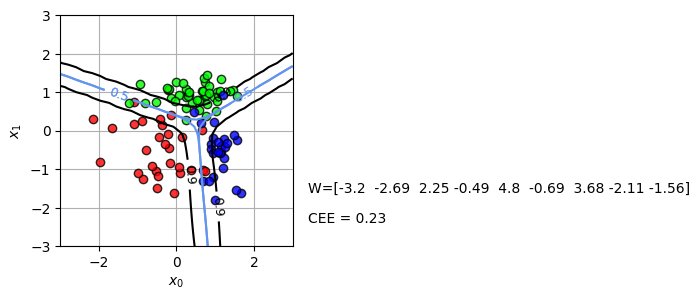

In [24]:
# 모델 등고선 2D 표시
def show_contour_logistic3(w):
    xn = 30  # 매개변수의 분할 수
    x0 = np.linspace(X_range0[0], X_range0[1], xn)
    x1 = np.linspace(X_range1[0], X_range1[1], xn)

    xx0, xx1 = np.meshgrid(x0, x1)
    y = np.zeros((xn, xn, 3))

    for i in range(xn):
        wk = logistic3(xx0[:, i], xx1[:, i], w)

        for j in range(3):
            y[:, i, j] = wk[:, j]

    for j in range(3):
        cont = plt.contour(xx0, xx1, y[:, :, j], levels=(0.5, 0.9), colors=['cornflowerblue', 'k'])
        cont.clabel(fmt='%1.1f', fontsize=9)

    plt.grid(True)

plt.figure(figsize=(3, 3))

show_data2(X, T3)
show_contour_logistic3(W)

plt.xlim(X_range0)
plt.ylim(X_range1)
plt.xlabel('$x_0$')
plt.ylabel('$x_1$')

# 오른쪽에 값 출력
plt.text(3.4, -1.6, 'W=' + str(np.round(W, 2)), fontsize=10)
plt.text(3.4, -2.4, 'CEE = {0:.2f}'.format(cee_logistic3(W, X, T3)), fontsize=10)

plt.show()
